# Bangla License Plate Deblurring - NAFNet Baseline
Nonlinear-activation-free network: U-shaped encoder-decoder built from NAF blocks (simple gate, simplified channel attention, layer norm), with a global residual to the blurry input. Trained with PSNR loss, same data and same image size as the other models so the comparison stays fair.

## Libraries

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 3060


d:\_deblur gan\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Paths and settings

In [2]:
CLEAN_DIR = r"D:\_deblur gan\new dataset\fixed cropped"
GAUSSIAN_DIR = r"D:\_deblur gan\new dataset\light_gaussian_blurred"
MOTION_DIR = r"D:\_deblur gan\new dataset\light_motion_blurred"

IMG_H = 128
IMG_W = 256
BATCH_SIZE = 8
EPOCHS = 10
LR = 1e-3
VAL_SPLIT = 0.1
SEED = 42

WIDTH = 32
ENC_BLOCKS = [1, 1, 1, 28]
MID_BLOCKS = 1
DEC_BLOCKS = [1, 1, 1, 1]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Dataset (images are loaded into RAM once, so training is faster)

In [3]:
valid_ext = (".png", ".jpg", ".jpeg", ".bmp")

clean_names = sorted([f for f in os.listdir(CLEAN_DIR) if f.lower().endswith(valid_ext)])
random.shuffle(clean_names)

val_count = int(len(clean_names) * VAL_SPLIT)
val_names = clean_names[:val_count]
train_names = clean_names[val_count:]


def make_pairs(names):
    pairs = []
    for name in names:
        for blur_dir in (GAUSSIAN_DIR, MOTION_DIR):
            blur_path = os.path.join(blur_dir, name)
            if os.path.exists(blur_path):
                pairs.append((blur_path, os.path.join(CLEAN_DIR, name)))
    return pairs


class PlateDataset(Dataset):
    def __init__(self, pairs):
        self.blur = []
        self.clean = []
        for blur_path, clean_path in tqdm(pairs):
            self.blur.append(self.load(blur_path))
            self.clean.append(self.load(clean_path))

    def __len__(self):
        return len(self.blur)

    def load(self, path):
        img = Image.open(path).convert("RGB").resize((IMG_W, IMG_H), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

    def __getitem__(self, i):
        return self.blur[i].float() / 127.5 - 1, self.clean[i].float() / 127.5 - 1


train_pairs = make_pairs(train_names)
val_pairs = make_pairs(val_names)

train_loader = DataLoader(PlateDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
val_loader = DataLoader(PlateDataset(val_pairs), batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("clean images:", len(clean_names))
print("train pairs:", len(train_pairs))
print("val pairs:", len(val_pairs))

100%|██████████| 398/398 [00:08<00:00, 47.13it/s]

clean images: 1991
train pairs: 3584
val pairs: 398


## NAF block

In [4]:
class LayerNorm2d(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.LayerNorm(ch)

    def forward(self, x):
        x = x.permute(0, 2, 3, 1)
        x = self.norm(x)
        return x.permute(0, 3, 1, 2)


class SimpleGate(nn.Module):
    def forward(self, x):
        x1, x2 = x.chunk(2, dim=1)
        return x1 * x2


class NAFBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        dw = ch * 2
        ffn = ch * 2

        self.norm1 = LayerNorm2d(ch)
        self.conv1 = nn.Conv2d(ch, dw, 1)
        self.conv2 = nn.Conv2d(dw, dw, 3, padding=1, groups=dw)
        self.gate = SimpleGate()
        self.sca = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(dw // 2, dw // 2, 1))
        self.conv3 = nn.Conv2d(dw // 2, ch, 1)

        self.norm2 = LayerNorm2d(ch)
        self.conv4 = nn.Conv2d(ch, ffn, 1)
        self.conv5 = nn.Conv2d(ffn // 2, ch, 1)

        self.beta = nn.Parameter(torch.zeros(1, ch, 1, 1))
        self.gamma = nn.Parameter(torch.zeros(1, ch, 1, 1))

    def forward(self, x):
        y = self.conv2(self.conv1(self.norm1(x)))
        y = self.gate(y)
        y = y * self.sca(y)
        y = self.conv3(y)
        x = x + y * self.beta

        y = self.conv4(self.norm2(x))
        y = self.gate(y)
        y = self.conv5(y)
        return x + y * self.gamma

## NAFNet

In [5]:
class NAFNet(nn.Module):
    def __init__(self, width, enc_blocks, mid_blocks, dec_blocks):
        super().__init__()
        self.intro = nn.Conv2d(3, width, 3, padding=1)
        self.ending = nn.Conv2d(width, 3, 3, padding=1)

        self.encoders = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.decoders = nn.ModuleList()
        self.ups = nn.ModuleList()

        ch = width
        for num in enc_blocks:
            self.encoders.append(nn.Sequential(*[NAFBlock(ch) for _ in range(num)]))
            self.downs.append(nn.Conv2d(ch, ch * 2, 2, stride=2))
            ch = ch * 2

        self.middle = nn.Sequential(*[NAFBlock(ch) for _ in range(mid_blocks)])

        for num in dec_blocks:
            self.ups.append(nn.Sequential(nn.Conv2d(ch, ch * 2, 1, bias=False), nn.PixelShuffle(2)))
            ch = ch // 2
            self.decoders.append(nn.Sequential(*[NAFBlock(ch) for _ in range(num)]))

    def forward(self, img):
        x = self.intro(img)

        skips = []
        for encoder, down in zip(self.encoders, self.downs):
            x = encoder(x)
            skips.append(x)
            x = down(x)

        x = self.middle(x)

        for decoder, up, skip in zip(self.decoders, self.ups, skips[::-1]):
            x = up(x)
            x = x + skip
            x = decoder(x)

        return self.ending(x) + img

## Loss functions and metrics (PSNR, SSIM, MAE)

In [6]:
def psnr_loss(fake, real):
    mse = ((fake - real) ** 2).mean(dim=(1, 2, 3))
    return (10 / np.log(10)) * torch.log(mse + 1e-8).mean()


def ssim(fake, real, window=11, sigma=1.5):
    fake = (fake.clamp(-1, 1) + 1) / 2
    real = (real + 1) / 2
    coords = torch.arange(window, dtype=torch.float32, device=fake.device) - window // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    kernel = (g[:, None] * g[None, :]).expand(3, 1, window, window).contiguous()
    mu_f = F.conv2d(fake, kernel, groups=3)
    mu_r = F.conv2d(real, kernel, groups=3)
    var_f = F.conv2d(fake * fake, kernel, groups=3) - mu_f ** 2
    var_r = F.conv2d(real * real, kernel, groups=3) - mu_r ** 2
    cov = F.conv2d(fake * real, kernel, groups=3) - mu_f * mu_r
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    score = ((2 * mu_f * mu_r + c1) * (2 * cov + c2)) / ((mu_f ** 2 + mu_r ** 2 + c1) * (var_f + var_r + c2))
    return score.mean(dim=(1, 2, 3))


def mae(fake, real):
    return ((fake.clamp(-1, 1) - real).abs() * 127.5).mean(dim=(1, 2, 3))


def evaluate(net, loader):
    net.eval()
    p_all, s_all, m_all = [], [], []
    with torch.no_grad():
        for blur, clean in loader:
            blur = blur.to(device)
            clean = clean.to(device)
            fake = net(blur)
            if isinstance(fake, (list, tuple)):
                fake = fake[0]
            fake = fake.clamp(-1, 1)
            mse = (((fake + 1) / 2 - (clean + 1) / 2) ** 2).mean(dim=(1, 2, 3))
            p_all.append(10 * torch.log10(1 / (mse + 1e-8)))
            s_all.append(ssim(fake, clean))
            m_all.append(mae(fake, clean))
    return torch.cat(p_all), torch.cat(s_all), torch.cat(m_all)

## Model, optimizer, scheduler

In [7]:
model = NAFNet(WIDTH, ENC_BLOCKS, MID_BLOCKS, DEC_BLOCKS).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.9), weight_decay=0)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print("params:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

params: 17.111907 M


## Blurry input metrics (reference before training)

In [8]:
p, s, m = evaluate(nn.Identity(), val_loader)
print(f"Blurry input | PSNR {p.mean():.2f} | SSIM {s.mean():.4f} | MAE {m.mean():.2f}")

Blurry input | PSNR 26.27 | SSIM 0.8171 | MAE 9.01


## Checkpoint setup

In [9]:
CKPT_DIR = "checkpoints_nafnet"
os.makedirs(CKPT_DIR, exist_ok=True)
LAST_PATH = os.path.join(CKPT_DIR, "last.pth")
BEST_PATH = os.path.join(CKPT_DIR, "best.pth")

start_epoch = 0
best_psnr = 0.0
history = {"loss": [], "val_psnr": [], "val_ssim": [], "val_mae": []}

RESUME = False

if RESUME and os.path.exists(LAST_PATH):
    ckpt = torch.load(LAST_PATH, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    history = ckpt["history"]
    best_psnr = ckpt["best_psnr"]
    start_epoch = ckpt["epoch"] + 1
    print("resumed from epoch", start_epoch)

## Training

In [10]:
for epoch in range(start_epoch, EPOCHS):
    model.train()
    loss_sum = 0

    for blur, clean in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"):
        blur = blur.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)

        optimizer.zero_grad()
        fake = model(blur)
        loss = psnr_loss(fake, clean)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.01)
        optimizer.step()

        loss_sum += loss.item()

    scheduler.step()

    p, s, m = evaluate(model, val_loader)
    val_psnr = p.mean().item()
    val_ssim = s.mean().item()
    val_mae = m.mean().item()

    history["loss"].append(loss_sum / len(train_loader))
    history["val_psnr"].append(val_psnr)
    history["val_ssim"].append(val_ssim)
    history["val_mae"].append(val_mae)

    print(f"epoch {epoch + 1} | loss {history['loss'][-1]:.4f} | val PSNR {val_psnr:.2f} | SSIM {val_ssim:.4f} | MAE {val_mae:.2f}")

    if history["val_psnr"][-1] > best_psnr:
        best_psnr = history["val_psnr"][-1]
        torch.save(model.state_dict(), BEST_PATH)

    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "history": history,
        "best_psnr": best_psnr,
        "epoch": epoch,
    }, LAST_PATH)

Epoch 1/10: 100%|██████████| 448/448 [01:54<00:00,  3.90it/s]


epoch 1 | loss -21.2106 | val PSNR 28.02 | SSIM 0.8397 | MAE 7.81


Epoch 2/10: 100%|██████████| 448/448 [01:38<00:00,  4.54it/s]


epoch 2 | loss -22.5309 | val PSNR 29.57 | SSIM 0.8840 | MAE 6.36


Epoch 3/10: 100%|██████████| 448/448 [01:39<00:00,  4.49it/s]


...

epoch 8 | loss -28.1132 | val PSNR 33.52 | SSIM 0.9418 | MAE 3.93


Epoch 9/10: 100%|██████████| 448/448 [01:41<00:00,  4.41it/s]


epoch 9 | loss -28.6255 | val PSNR 33.86 | SSIM 0.9438 | MAE 3.78


Epoch 10/10: 100%|██████████| 448/448 [01:43<00:00,  4.34it/s]


epoch 10 | loss -28.9416 | val PSNR 33.92 | SSIM 0.9443 | MAE 3.75


## Training curves

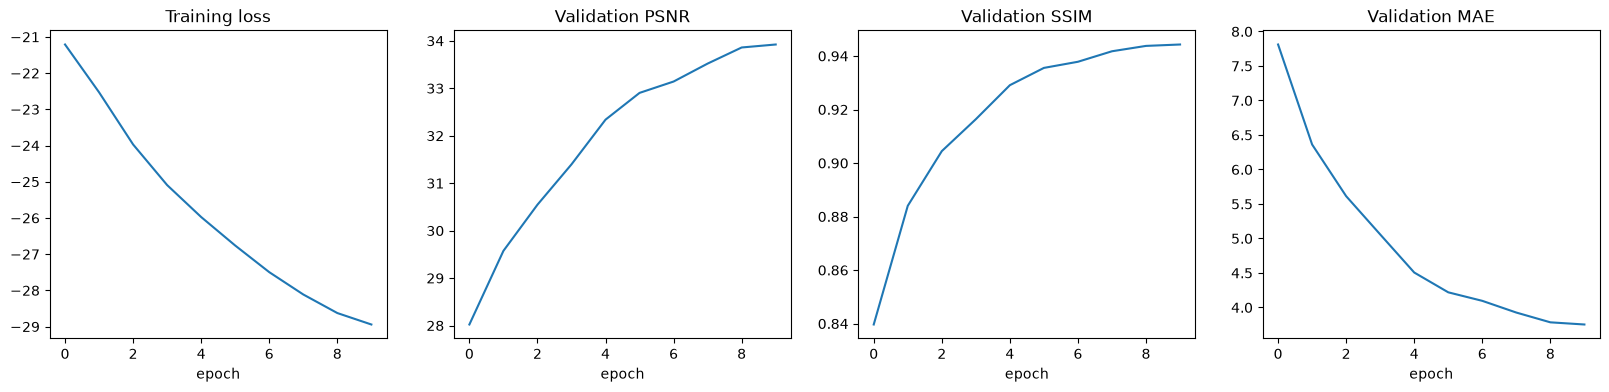

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history["loss"])
axes[0].set_title("Training loss")
axes[1].plot(history["val_psnr"])
axes[1].set_title("Validation PSNR")
axes[2].plot(history["val_ssim"])
axes[2].set_title("Validation SSIM")
axes[3].plot(history["val_mae"])
axes[3].set_title("Validation MAE")
for ax in axes:
    ax.set_xlabel("epoch")
plt.show()

## Visual results

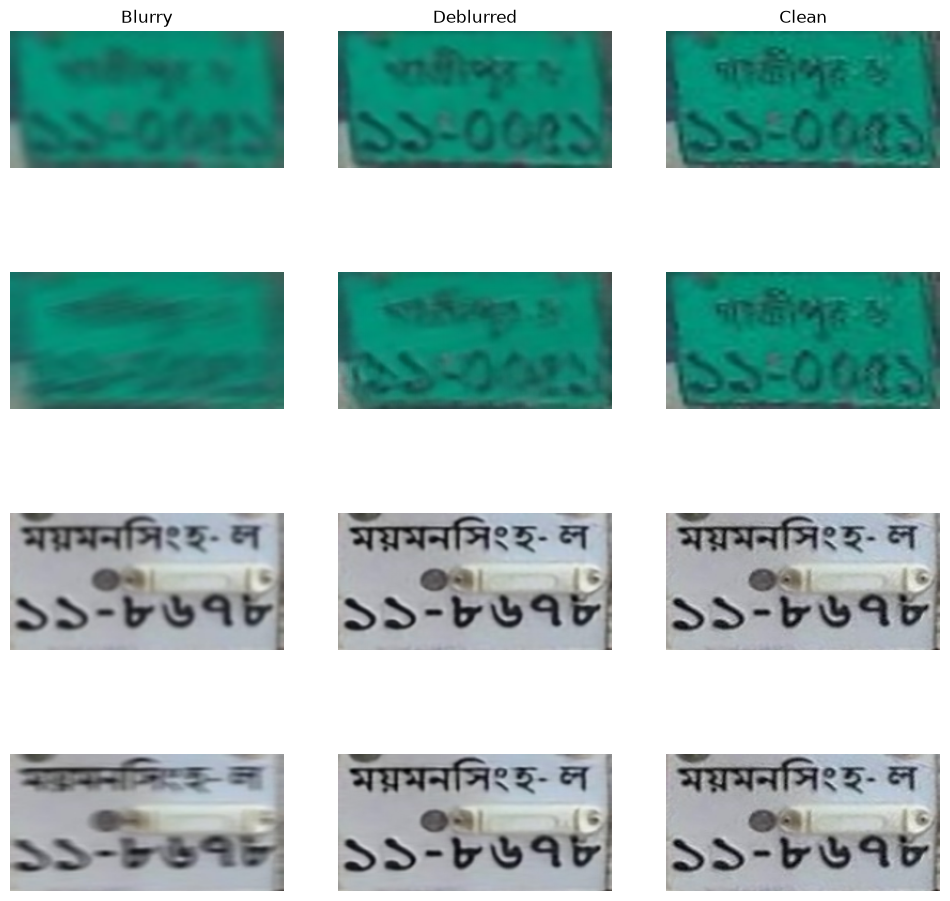

In [12]:
model.eval()
blur, clean = next(iter(val_loader))
with torch.no_grad():
    fake = model(blur.to(device)).clamp(-1, 1).cpu()


def show(t):
    return ((t.permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy()


n = min(4, blur.size(0))
fig, axes = plt.subplots(n, 3, figsize=(12, 3 * n), squeeze=False)
for i in range(n):
    axes[i][0].imshow(show(blur[i]))
    axes[i][1].imshow(show(fake[i]))
    axes[i][2].imshow(show(clean[i]))
    for j in range(3):
        axes[i][j].axis("off")
axes[0][0].set_title("Blurry")
axes[0][1].set_title("Deblurred")
axes[0][2].set_title("Clean")
plt.show()

Final evaluation with the best weights

In [13]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
p, s, m = evaluate(model, val_loader)
p, s, m = p.cpu().numpy(), s.cpu().numpy(), m.cpu().numpy()

is_motion = np.array([os.path.dirname(b) == MOTION_DIR for b, _ in val_pairs])
groups = {"all": np.ones(len(p), dtype=bool), "gaussian": ~is_motion, "motion": is_motion}

for name, mask in groups.items():
    print(f"{name:9s} | PSNR {p[mask].mean():.2f} | SSIM {s[mask].mean():.4f} | MAE {m[mask].mean():.2f}")

C:\Users\Sagar\AppData\Local\Temp\ipykernel_12136\3350501376.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(BEST_PATH, map_location=dev

all       | PSNR 33.92 | SSIM 0.9443 | MAE 3.75
gaussian  | PSNR 35.76 | SSIM 0.9585 | MAE 3.02
motion    | PSNR 32.08 | SSIM 0.9301 | MAE 4.49
